In [13]:
import io
import os
import contextlib

import numpy as np
import torch


torch.set_default_dtype(torch.float64)


In [14]:
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt  # pyplot imported AFTER backend is set
import matplotlib.gridspec as gridspec

In [15]:
CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ       = 10000
NOISE_SCALE    = 0.1
SEED           = 0

CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

for p, label in [(CKPT_BS2, 'bs=2  (noisy)'), (CKPT_BS100, 'bs=100 (noisy)')]:
    status = '✓' if os.path.exists(p) else '✗ NOT FOUND'
    print(f"  {label:16s}: {status}")
    print(f"                   {p}")

  bs=2  (noisy)   : ✓
                   ./checkpoints/kepler_cv_blocksize_elm/model_block_size_2_num_trajectories_10000_noise_scale_0.1.pt
  bs=100 (noisy)  : ✓
                   ./checkpoints/kepler_cv_blocksize_elm/model_block_size_100_num_trajectories_10000_noise_scale_0.1.pt


In [16]:
import sys
sys.path.insert(0, '.')

from analysis.model import load_from_checkpoint
from analysis.elm import collect, sample_orbit_windows

def load_model(path, label):
    with contextlib.redirect_stdout(io.StringIO()):
        model, ckpt = load_from_checkpoint(path, device='cpu')
    model.eval()
    step = ckpt.get('step', '?')
    cfg  = model.config
    print(f"  {label}: step={step}, n_layer={cfg.n_layer}, "
          f"n_head={cfg.n_head}, n_embd={cfg.n_embd}, "
          f"block_size={cfg.block_size}")
    return model, ckpt

print("Loading models...")
model_bs2,   ckpt_bs2   = load_model(CKPT_BS2,   'bs=2  (noise=0.1)')
model_bs100, ckpt_bs100 = load_model(CKPT_BS100, 'bs=100 (noise=0.1)')

Loading models...
  bs=2  (noise=0.1): step=20000, n_layer=2, n_head=1, n_embd=32, block_size=2
  bs=100 (noise=0.1): step=20000, n_layer=2, n_head=1, n_embd=32, block_size=100


Running ELM scatter (last token only)...
  bs=2  (50 windows)...
  bs=100 (50 windows)...
Done.


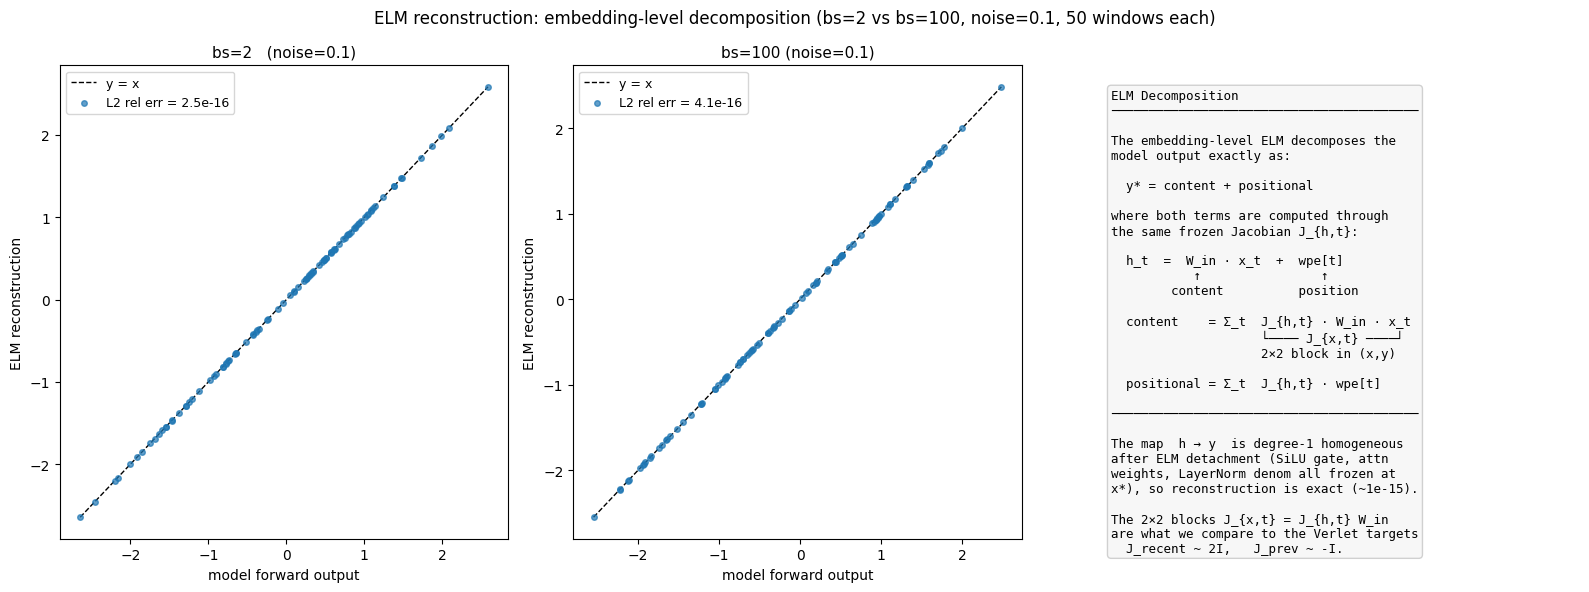

In [17]:
def elm_scatter_data_last(model, block_size, n_windows, seed=0):
    """ELM reconstruction for the last output token only — fast for large block sizes."""
    windows = sample_orbit_windows(block_size, n_windows, seed=seed)
    model_vals, emb_vals = [], []

    for w in windows:
        xs = torch.tensor(w, dtype=torch.float64).unsqueeze(0)  # (1, T, 2)

        # model forward — take only last token output
        with torch.no_grad():
            y_model, _ = model(xs)
        y_last = y_model[0, -1, :].detach().numpy()  # (2,)

        # build h* = W_in @ x + wpe, same as compute_detached_jacobians_embedding
        T   = xs.shape[1]
        pos = torch.arange(0, T, dtype=torch.long)
        x_emb   = model.embed_continuous(xs)           # (1, T, n_embd)
        pos_emb = model.transformer.wpe(pos)           # (T, n_embd)
        h_star  = (x_emb + pos_emb).detach()           # (1, T, n_embd)

        model.detach_for_elm = True
        model.eval()

        # differentiate only the last output token w.r.t. each h_t
        def last_output(h_in):
            out = model.forward_from_embedding(h_in)   # (1, T, 2)
            return out[0, -1, :]                       # (2,) — last token only

        content_last    = torch.zeros(2, dtype=torch.float64)
        positional_last = torch.zeros(2, dtype=torch.float64)

        for t in range(T):
            before = h_star[0, :t, :].detach()
            after  = h_star[0, t+1:, :].detach()

            def fwd(h_t, before=before, after=after):
                h_in = torch.cat([before, h_t.unsqueeze(0), after], dim=0).unsqueeze(0)
                with torch.enable_grad():
                    return last_output(h_in)

            h_t = h_star[0, t, :].detach().requires_grad_(True)
            J_ht = torch.autograd.functional.jacobian(
                fwd, h_t, create_graph=False, strict=False
            )  # (2, n_embd)

            W_in = model.input_embedding.weight        # (n_embd, 2)
            J_xt = J_ht @ W_in                         # (2, 2)

            content_last    += J_xt @ xs[0, t, :]
            positional_last += J_ht @ pos_emb[t]

        model.detach_for_elm = False

        recon = (content_last + positional_last).detach().numpy()  # (2,)

        # store only the last token values — both model and recon are (2,)
        model_vals.append(y_last)
        emb_vals.append(recon)

    return np.concatenate(model_vals), np.concatenate(emb_vals)

N_VERIFY = 50
N_VERIFY_BS2 = 50
N_VERIFY_BS100 = 50


print(f"Running ELM scatter (last token only)...")
print(f"  bs=2  ({N_VERIFY_BS2} windows)...")
mv_2,   ev_2   = elm_scatter_data_last(model_bs2,   2,   N_VERIFY_BS2,   seed=SEED)
print(f"  bs=100 ({N_VERIFY_BS100} windows)...")
mv_100, ev_100 = elm_scatter_data_last(model_bs100, 100, N_VERIFY_BS100, seed=SEED)
print("Done.")

fig = plt.figure(figsize=(16, 6))
gs  = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 1.1], figure=fig)

for col, (mv, ev, label) in enumerate([
    (mv_2,   ev_2,   'bs=2   (noise=0.1)'),
    (mv_100, ev_100, 'bs=100 (noise=0.1)'),
]):
    ax  = fig.add_subplot(gs[col])
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo  = float(min(mv.min(), ev.min()))
    hi  = float(max(mv.max(), ev.max()))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
    ax.scatter(mv, ev, s=16, c='tab:blue', alpha=0.7, zorder=2,
               label=f'L2 rel err = {err:.1e}')
    ax.set_xlabel('model forward output', fontsize=10)
    ax.set_ylabel('ELM reconstruction', fontsize=10)
    ax.set_title(label, fontsize=11)
    ax.legend(fontsize=9)

# third panel: text description
ax_txt = fig.add_subplot(gs[2])
ax_txt.axis('off')
description = (
    "ELM Decomposition\n"
    "─────────────────────────────────────────\n\n"
    "The embedding-level ELM decomposes the\n"
    "model output exactly as:\n\n"
    "  y* = content + positional\n\n"
    "where both terms are computed through\n"
    "the same frozen Jacobian J_{h,t}:\n\n"
    "  h_t  =  W_in · x_t  +  wpe[t]\n"
    "           ↑                ↑\n"
    "        content          position\n\n"
    "  content    = Σ_t  J_{h,t} · W_in · x_t\n"
    "                    └──── J_{x,t} ────┘\n"
    "                    2×2 block in (x,y)\n\n"
    "  positional = Σ_t  J_{h,t} · wpe[t]\n\n"
    "─────────────────────────────────────────\n\n"
    "The map  h → y  is degree-1 homogeneous\n"
    "after ELM detachment (SiLU gate, attn\n"
    "weights, LayerNorm denom all frozen at\n"
    "x*), so reconstruction is exact (~1e-15).\n\n"
    "The 2×2 blocks J_{x,t} = J_{h,t} W_in\n"
    "are what we compare to the Verlet targets\n"
    "  J_recent ~ 2I,   J_prev ~ -I."
)
ax_txt.text(0.05, 0.95, description, transform=ax_txt.transAxes,
            fontsize=9, verticalalignment='top', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='#f7f7f7',
                      edgecolor='#cccccc', alpha=0.9))

fig.suptitle(
    f'ELM reconstruction: embedding-level decomposition '
    f'(bs=2 vs bs=100, noise=0.1, {N_VERIFY} windows each)',
    fontsize=12
)
fig.tight_layout()
plt.show()

trajs (10000, 100, 2), orbital_params 10000
Probing bs=2 ...
Hooks registered for 2 transformer blocks:
  For each block: attn_output, after_attn_merge, mlp_output, after_mlp_merge, mlp_hidden
  Additional: input_embed, after_pos_emb, after_ln_f
  Total hooks: 13
Probing bs=100 ...
Hooks registered for 2 transformer blocks:
  For each block: attn_output, after_attn_merge, mlp_output, after_mlp_merge, mlp_hidden
  Additional: input_embed, after_pos_emb, after_ln_f
  Total hooks: 13
done


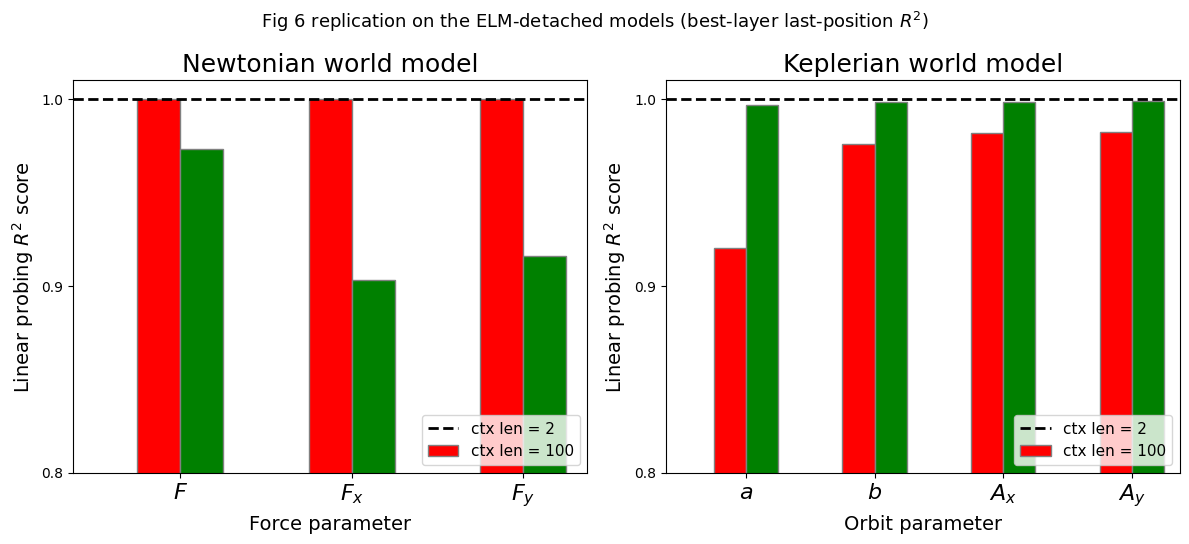


          target     bs=2   bs=100
-- NEWTON
     F_magnitude   1.0000   0.9731
              Fx   1.0000   0.9033
              Fy   1.0000   0.9160
-- KEPLER
               a   0.9201   0.9971
               b   0.9761   0.9985
           LRL_x   0.9821   0.9986
           LRL_y   0.9826   0.9991


In [18]:
# Cell 6 — Liu et al. Fig 6: Newtonian (force) vs Keplerian (orbit) linear probes
#
# NOTE: ELM detachment changes only the BACKWARD pass (gradients); forward
# activations and weights are identical, and probing runs with detach_for_elm=False.
# So ELM cannot alter probing — this reproduces Fig 6 on the project's checkpoints.
from analysis.data import (
    load_trajectories, load_orbital_params, chop_trajectories_into_sequences,
)
from analysis.probing import (
    setup_activation_hooks, collect_activations, run_linear_probes, run_geometry_probes,
)

N_PROBE = 1000

with contextlib.redirect_stdout(io.StringIO()):
    trajs    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=NUM_TRAJ))
    o_params = load_orbital_params(DATA_DIR, num_trajectories_needed=NUM_TRAJ)
print(f"trajs {trajs.shape}, orbital_params {len(o_params)}")

def make_windows(block_size, n_probe, seed):
    """Chop into windows + map each to its source trajectory. Caps eff block size
    to num_points-1 so block_size=100 doesn't yield zero windows (length-99)."""
    npnts  = trajs.shape[1]
    eff_bs = min(block_size, npnts - 1)
    with contextlib.redirect_stdout(io.StringIO()):
        inputs, _ = chop_trajectories_into_sequences(trajs, eff_bs, seed=seed)
    seqs_per_traj = max(1, npnts // eff_bs)
    traj_idx = np.arange(len(inputs)) // seqs_per_traj
    rng = np.random.default_rng(seed)
    sel = rng.choice(len(inputs), size=min(n_probe, len(inputs)), replace=False)
    return inputs[sel].astype(np.float64), np.clip(traj_idx[sel], 0, len(o_params) - 1)

def probe_model(model, block_size, seed=SEED):
    windows, traj_idx = make_windows(block_size, N_PROBE, seed)
    hooks, act = setup_activation_hooks(model)
    with contextlib.redirect_stdout(io.StringIO()):
        _, gforce = collect_activations(model, torch.tensor(windows), None, act)
        newton = run_linear_probes(act, gforce)
        kepler = run_geometry_probes(act, o_params, traj_idx)
    for h in hooks:
        h.remove()
    return newton, kepler

print("Probing bs=2 ...");   newton_2,   kepler_2   = probe_model(model_bs2,   2)
print("Probing bs=100 ..."); newton_100, kepler_100 = probe_model(model_bs100, 100)
print("done")

# best-over-layers, last-position probe (matches fig6 'postfix = _last')
def best_r2(probe_results, target, key='r2_last'):
    return max(layer[target][key] for layer in probe_results.values() if target in layer)

# exact fig6 quantities
NEWTON = [('F_magnitude', r'$F$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, xlabel, items, p2, p100) in zip(axes, [
        ('Newtonian world model', 'Force parameter',  NEWTON, newton_2, newton_100),
        ('Keplerian world model', 'Orbit parameter',  KEPLER, kepler_2, kepler_100)]):
    targets = [t for t, _ in items]
    ticklab = [lab for _, lab in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25
    br1 = np.arange(len(targets)); br2 = br1 + bw
    ax.bar(br1, r2_2,   bw, color='r', edgecolor='grey')
    ax.bar(br2, r2_100, bw, color='g', edgecolor='grey')
    ax.plot([-0.5, len(targets) - 0.5], [1, 1], '--', color='black', lw=2)
    ax.set_xlim(-0.5, len(targets) - 0.5)
    ax.set_ylim(0.8, 1.01); ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab, fontsize=16)
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel(r'Linear probing $R^2$ score', fontsize=14)
    ax.set_title(title, fontsize=18)
    ax.legend(['ctx len = 2', 'ctx len = 100'], fontsize=11, loc='lower right')
fig.suptitle('Fig 6 replication on the ELM-detached models (best-layer last-position $R^2$)',
             fontsize=13)
fig.tight_layout()
plt.show()

print(f"\n{'target':>16} {'bs=2':>8} {'bs=100':>8}")
for grp, p2, p100, items in [('NEWTON', newton_2, newton_100, NEWTON),
                             ('KEPLER', kepler_2, kepler_100, KEPLER)]:
    print(f"-- {grp}")
    for t, _ in items:
        print(f"  {t:>14} {best_r2(p2, t):>8.4f} {best_r2(p100, t):>8.4f}")